# Customer Churn Prediction

## 1. Project Overview

**Goal:** predict whether a customer will leave the service (**churn**) using customer attributes such as age, tenure, support calls and payment delay. A short, plain-language explanation of each prediction is produced with the Gemini API.

**Dataset:** `customer_churn_dataset.csv` (one row per customer).

| Column | Meaning |
|---|---|
| `CustomerID` | Row identifier. **Not used as a feature** (see Section 10). |
| `Age`, `Gender`, `Tenure`, `Usage Frequency`, `Support Calls`, `Payment Delay`, `Subscription Type`, `Contract Length`, `Total Spend`, `Last Interaction` | Customer attributes used as model inputs |
| `Churn` | **Target.** `1` = customer churned (the *positive class*), `0` = customer stayed |

**Workflow:** load data -> quality checks -> exploratory analysis -> preprocessing pipeline -> train/test split -> train three models (Logistic Regression, Decision Tree, Random Forest) -> evaluate -> cross-validation and leakage checks -> choose the final model -> predict for a single customer -> optional Gemini explanation.

> **Important caveat (details in Sections 10 and 14):** Decision Tree and Random Forest score about 99.8% on this dataset. The checks in Section 10 indicate this reflects how the dataset itself is built (churn behaves like a near-deterministic rule of the features, and the file contains an unusual 100%-churn block of rows), not necessarily how well the model would work on real customers.

### How to run this notebook
1. Put `customer_churn_dataset.csv` in the **same folder as this notebook** (or set the environment variable `CHURN_DATA_PATH` to its full path).
2. Install packages: `pip install numpy pandas matplotlib seaborn scikit-learn` (and `pip install -U google-genai` only if you want the live Gemini explanation).
3. *(Optional)* set your Gemini key **before** starting Jupyter, e.g. `export GEMINI_API_KEY="..."` (macOS/Linux) or `setx GEMINI_API_KEY "..."` (Windows). The key is never written into this notebook.
4. Choose **Kernel -> Restart & Run All**. Without a key the notebook still runs; the Gemini step is skipped and the ML prediction is unaffected.

## 2. Imports and Configuration

All imports and settings live in one place. A fixed random seed (`RANDOM_STATE`) makes the results reproducible.

In [1]:
import os
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, make_scorer,
)

# ---- Project settings ----
RANDOM_STATE = 42          # fixed seed -> reproducible results
TEST_SIZE = 0.2            # 80% train / 20% test
CV_FOLDS = 5               # cross-validation folds (used on the training set only)
TARGET = "Churn"           # column we want to predict
ID_COLUMN = "CustomerID"   # identifier; never used as a feature
POSITIVE_CLASS = 1         # 1 = churned. Precision/recall/F1 are reported for this class.
DATA_FILE = "customer_churn_dataset.csv"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Configuration loaded.")

Configuration loaded.


## 3. Dataset Loading

The loader looks for the CSV in this order: the `CHURN_DATA_PATH` environment variable, the current folder, then a `data/` sub-folder. If the file is not found it stops with a clear message (the original version silently returned `None`, which caused a confusing error later).

In [2]:
def find_data_file(file_name=DATA_FILE):
    """Return the first existing path for the dataset, or raise a helpful error."""
    candidates = [os.environ.get("CHURN_DATA_PATH"), file_name, os.path.join("data", file_name)]
    candidates = [c for c in candidates if c]
    for path in candidates:
        if os.path.isfile(path):
            return path
    raise FileNotFoundError(
        f"Could not find '{file_name}'. Looked in: {candidates}. "
        "Place the CSV next to this notebook or set the CHURN_DATA_PATH environment variable."
    )


def load_data(file_path):
    """Load the dataset from a CSV file and return it as a DataFrame."""
    df = pd.read_csv(file_path)
    print(f"Dataset loaded successfully from: {file_path}")
    return df


df = load_data(find_data_file())
df.head()

Dataset loaded successfully from: customer_churn_dataset.csv


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


## 4. Data Quality Checks

Before modelling we check the shape, data types, missing values, duplicates, category labels and value ranges. We only fix things that are actually broken.

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes.to_string())

missing = df.isnull().sum()
print("\nMissing values per column:")
print(missing.to_string())
print("Total missing values:", int(missing.sum()))

print("\nDuplicate checks:")
print("  Fully duplicated rows:                       ", int(df.duplicated().sum()))
print("  Duplicated rows ignoring CustomerID:         ", int(df.drop(columns=ID_COLUMN).duplicated().sum()))
print("  CustomerID unique?                           ", df[ID_COLUMN].is_unique)
print("  CustomerID runs from", df[ID_COLUMN].min(), "to", df[ID_COLUMN].max(), "with", len(df), "rows")

Dataset shape (rows, columns): (64374, 12)

Data types:
CustomerID           int64
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64
Churn                int64

Missing values per column:
CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
Total missing values: 0

Duplicate checks:
  Fully duplicated rows:                        0
  Duplicated rows ignoring CustomerID:          0
  CustomerID unique?                            True
  CustomerID runs from 1 to 64374 with 64374 rows


In [4]:
# Column groups (select by "not numeric" so this works on both pandas 2 and pandas 3 without warnings)
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:    ", numeric_columns)
print("Categorical columns:", categorical_columns)

# Unexpected categories / spelling variants?
for col in categorical_columns:
    values = df[col].unique().tolist()
    same_after_cleaning = df[col].str.strip().str.lower().nunique() == df[col].nunique()
    print(f"\n{col}: {values}  | no case/whitespace variants: {same_after_cleaning}")

# Target values must be only 0 and 1
assert set(df[TARGET].unique()) <= {0, 1}, "Target contains unexpected values"
print("\nTarget values:", sorted(df[TARGET].unique().tolist()))

# Impossible values?
print("\nNegative values per numeric column:")
print((df[numeric_columns] < 0).sum().to_string())

df[numeric_columns].describe().T

Numeric columns:     ['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn']
Categorical columns: ['Gender', 'Subscription Type', 'Contract Length']

Gender: ['Female', 'Male']  | no case/whitespace variants: True

Subscription Type: ['Basic', 'Standard', 'Premium']  | no case/whitespace variants: True

Contract Length: ['Monthly', 'Annual', 'Quarterly']  | no case/whitespace variants: True

Target values: [0, 1]

Negative values per numeric column:
CustomerID          0
Age                 0
Tenure              0
Usage Frequency     0
Support Calls       0
Payment Delay       0
Total Spend         0
Last Interaction    0
Churn               0


,count,mean,std,min,25%,50%,75%,max
CustomerID,64374.0,32187.500000,18583.317451,1.0,16094.25,32187.5,48280.75,64374.0
Age,64374.0,41.970982,13.924911,18.0,30.00,42.0,54.00,65.0
Tenure,64374.0,31.994827,17.098234,1.0,18.00,33.0,47.00,60.0
Usage Frequency,64374.0,15.080234,8.816470,1.0,7.00,15.0,23.00,30.0
Support Calls,64374.0,5.400690,3.114005,0.0,3.00,6.0,8.00,10.0
Payment Delay,64374.0,17.133952,8.852211,0.0,10.00,19.0,25.00,30.0
Total Spend,64374.0,541.023379,260.874809,100.0,313.00,534.0,768.00,1000.0
Last Interaction,64374.0,15.498850,8.638436,1.0,8.00,15.0,23.00,30.0
Churn,64374.0,0.473685,0.499311,0.0,0.00,0.0,1.00,1.0


**Data-quality findings (from the output above):**

* 64,374 rows and 12 columns; **no missing values** and **no duplicate rows** (also none when `CustomerID` is ignored). So no imputation and no row removal was applied, because nothing needed fixing.
* `CustomerID` is unique and runs 1 to 64,374; it is an identifier, not a customer attribute.
* Category labels are clean (`Gender`: 2 values, `Subscription Type`: 3, `Contract Length`: 3) with no spelling or case variants. The target contains only 0 and 1. No negative values.
* Value ranges are plausible: Age 18-65, Tenure 1-60, Usage Frequency 1-30, Support Calls 0-10, Payment Delay 0-30, Total Spend 100-1000, Last Interaction 1-30.
* Under pandas 3, text columns have dtype `str` rather than `object`. The original code selected columns with `include=[object]`, which raised `Pandas4Warning`; the notebook now selects text columns as "not numeric", which works on pandas 2 and 3 without warnings.

## 5. Exploratory Data Analysis (EDA)

EDA helps us understand which customer attributes are related to churn. Everything here is descriptive; relationships shown are **associations**, not proof of cause.

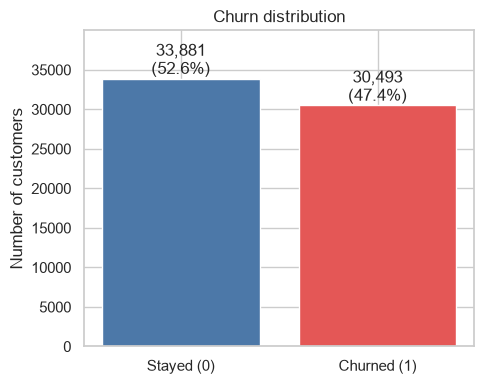

Churn rate: 47.4%  -> the classes are fairly balanced, so accuracy is not badly distorted, but we still report precision, recall and F1 for the churn class.


In [5]:
# 5.1 Churn distribution
churn_counts = df[TARGET].value_counts().sort_index()
churn_pct = df[TARGET].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Stayed (0)", "Churned (1)"], churn_counts.values, color=["#4C78A8", "#E45756"])
for i, (count, pct) in enumerate(zip(churn_counts.values, churn_pct.values)):
    ax.text(i, count, f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, churn_counts.max() * 1.18)
ax.set_title("Churn distribution")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()
print(f"Churn rate: {churn_pct[1]:.1f}%  -> the classes are fairly balanced, so accuracy is not badly distorted, "
      "but we still report precision, recall and F1 for the churn class.")

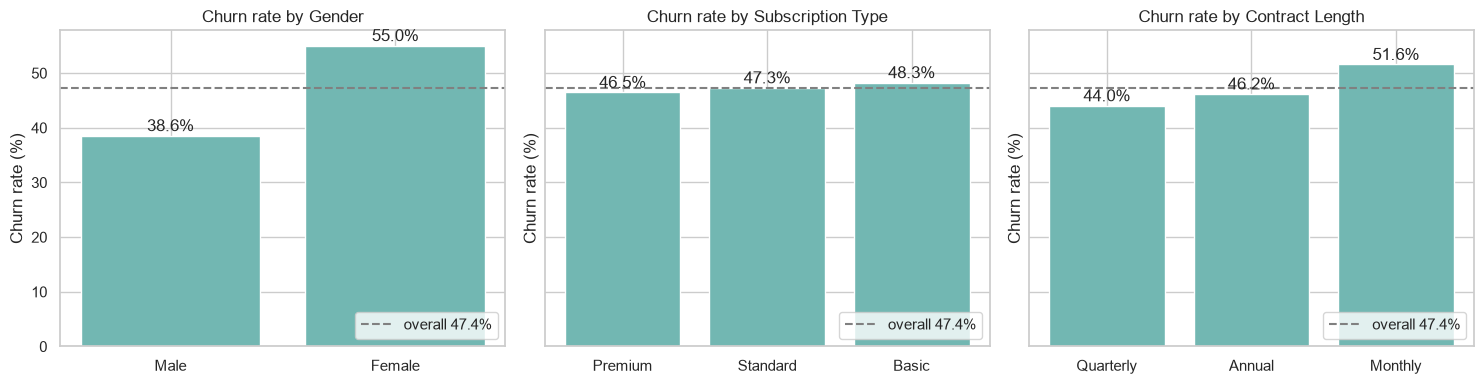


Gender vs Churn (row % = share of each group that stayed / churned)
Churn      0     1
Gender            
Female  45.0  55.0
Male    61.4  38.6

Subscription Type vs Churn (row % = share of each group that stayed / churned)
Churn                 0     1
Subscription Type            
Basic              51.7  48.3
Premium            53.5  46.5
Standard           52.7  47.3

Contract Length vs Churn (row % = share of each group that stayed / churned)
Churn               0     1
Contract Length            
Annual           53.8  46.2
Monthly          48.4  51.6
Quarterly        56.0  44.0


In [6]:
# 5.2 Churn rate by categorical feature
overall_rate = df[TARGET].mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, categorical_columns):
    rate = df.groupby(col)[TARGET].mean().mul(100).sort_values()
    ax.bar(rate.index, rate.values, color="#72B7B2")
    ax.axhline(overall_rate, color="grey", linestyle="--", label=f"overall {overall_rate:.1f}%")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

for col in categorical_columns:
    print(f"\n{col} vs Churn (row % = share of each group that stayed / churned)")
    print((pd.crosstab(df[col], df[TARGET], normalize="index") * 100).round(1).to_string())

Average value of each numeric feature, by churn status:


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0,41.13,28.83,16.04,4.5,12.45,560.54,15.52
1,42.90,35.52,14.01,6.4,22.33,519.34,15.47


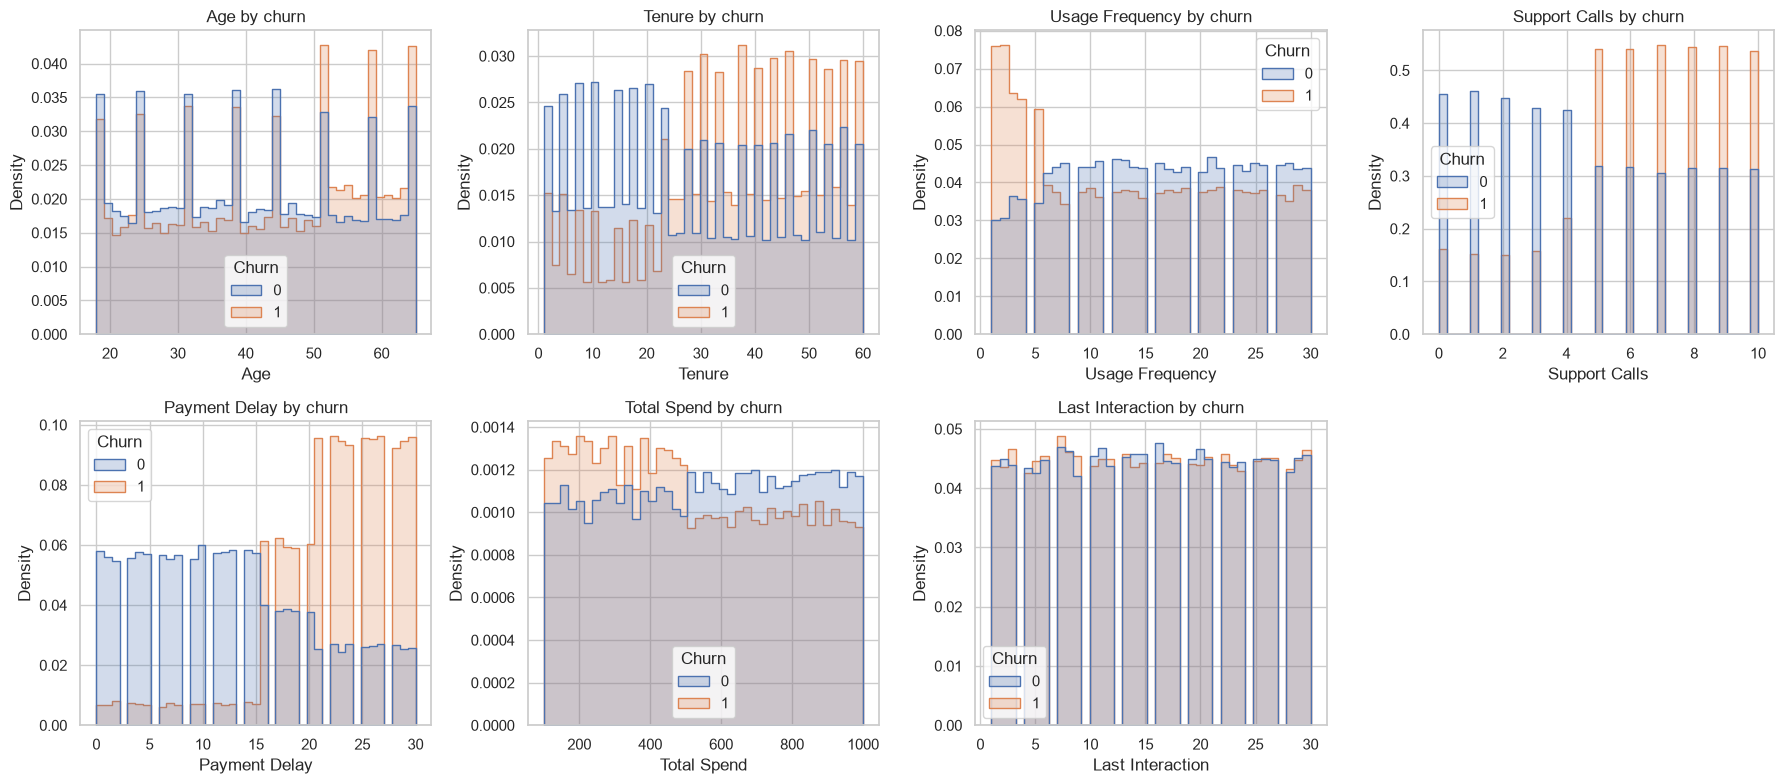

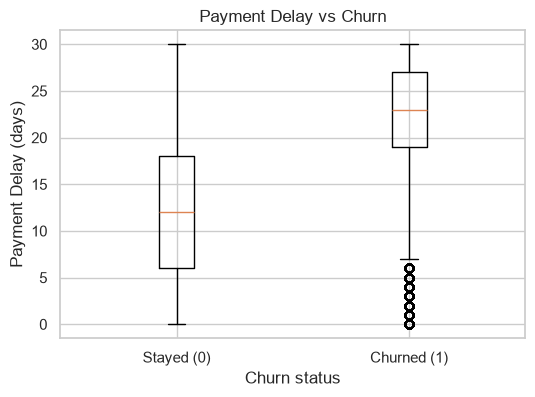

In [7]:
# 5.3 Numeric features: averages and distributions by churn status
numeric_features_eda = [c for c in numeric_columns if c not in (ID_COLUMN, TARGET)]
print("Average value of each numeric feature, by churn status:")
display(df.groupby(TARGET)[numeric_features_eda].mean().round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), numeric_features_eda):
    sns.histplot(data=df, x=col, hue=TARGET, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} by churn")
for ax in axes.ravel()[len(numeric_features_eda):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.boxplot([df.loc[df[TARGET] == 0, "Payment Delay"], df.loc[df[TARGET] == 1, "Payment Delay"]], tick_labels=["Stayed (0)", "Churned (1)"])
plt.title("Payment Delay vs Churn")
plt.xlabel("Churn status")
plt.ylabel("Payment Delay (days)")
plt.show()

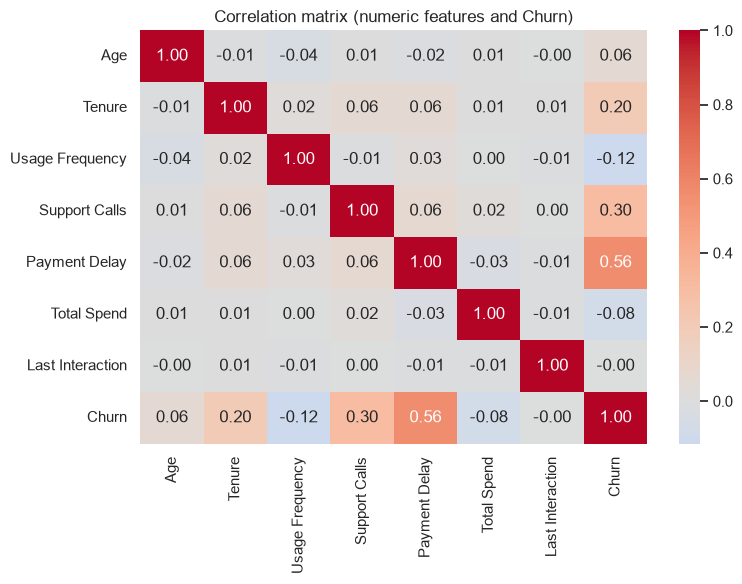

Correlation with Churn:
Payment Delay       0.557
Support Calls       0.305
Tenure              0.195
Age                 0.063
Last Interaction   -0.003
Total Spend        -0.079
Usage Frequency    -0.115


In [8]:
# 5.4 Correlation between numeric features and churn (CustomerID excluded on purpose)
corr = df[numeric_features_eda + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features and Churn)")
plt.tight_layout()
plt.show()
print("Correlation with Churn:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

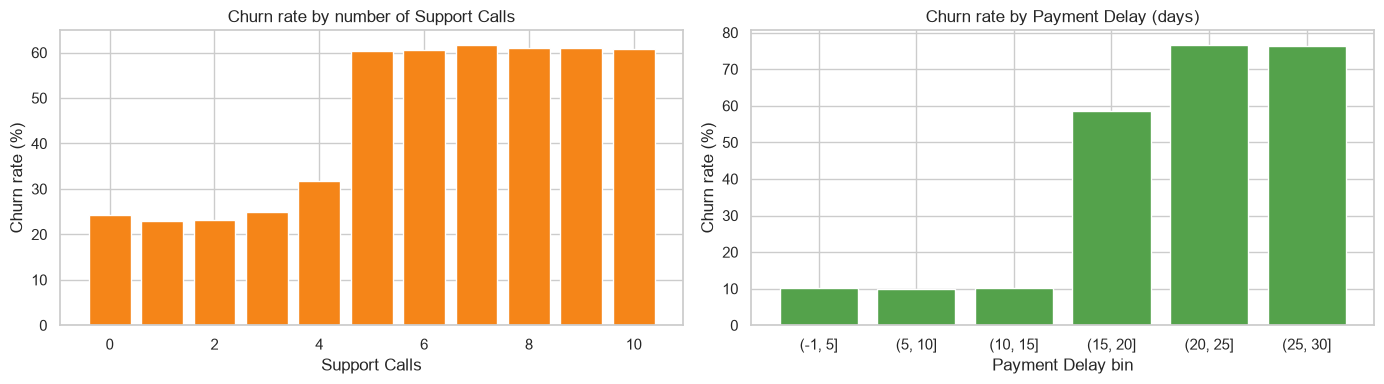

In [9]:
# 5.5 Churn rate by Support Calls and by Payment Delay (looking for thresholds)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

rate_calls = df.groupby("Support Calls")[TARGET].mean() * 100
axes[0].bar(rate_calls.index, rate_calls.values, color="#F58518")
axes[0].set_title("Churn rate by number of Support Calls")
axes[0].set_xlabel("Support Calls"); axes[0].set_ylabel("Churn rate (%)")

delay_bins = pd.cut(df["Payment Delay"], bins=[-1, 5, 10, 15, 20, 25, 30])
rate_delay = df.groupby(delay_bins, observed=True)[TARGET].mean() * 100
axes[1].bar(rate_delay.index.astype(str), rate_delay.values, color="#54A24B")
axes[1].set_title("Churn rate by Payment Delay (days)")
axes[1].set_xlabel("Payment Delay bin"); axes[1].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

* **X (features)** = every column except `Churn` (target) and `CustomerID` (identifier).
* **Numeric features** are standardised with `StandardScaler`; **categorical features** are one-hot encoded with `OneHotEncoder(handle_unknown="ignore")`.
* Both steps live inside a scikit-learn `Pipeline` + `ColumnTransformer`, so the preprocessing is **fitted only on the training data** and applied identically at prediction time.
* The original notebook shared one `Preprocessor` object between all three pipelines. That works by accident but is fragile, so a small factory function now creates a fresh preprocessor for each model.
* No imputation is added: Section 4 found no missing values.

In [10]:
x = df.drop(columns=[TARGET, ID_COLUMN])
y = df[TARGET]

numerical_features = x.select_dtypes(include="number").columns.tolist()
categorical_features = x.select_dtypes(exclude="number").columns.tolist()

print("Features (X):", x.shape, "| Target (y):", y.shape)
print("Numerical features:  ", numerical_features)
print("Categorical features:", categorical_features)


def build_preprocessor(num_cols, cat_cols):
    """Create a NEW (unfitted) preprocessor."""
    return ColumnTransformer(transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])


def build_pipeline(classifier, num_cols=None, cat_cols=None):
    """Preprocessing + classifier in one object."""
    num_cols = numerical_features if num_cols is None else num_cols
    cat_cols = categorical_features if cat_cols is None else cat_cols
    return Pipeline([
        ("preprocessor", build_preprocessor(num_cols, cat_cols)),
        ("classifier", classifier),
    ])

Features (X): (64374, 10) | Target (y): (64374,)
Numerical features:   ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical features: ['Gender', 'Subscription Type', 'Contract Length']


## 7. Train-Test Split

80% of the rows are used for training and 20% are held back for the final test. `stratify=y` keeps the churn share the same in both parts and `random_state` makes the split reproducible. The test set is **not** used for fitting the preprocessing, for choosing the model, or for any tuning.

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("x_train:", x_train.shape, "| x_test:", x_test.shape)
print("Churn share  - full data: {:.4f} | train: {:.4f} | test: {:.4f}".format(y.mean(), y_train.mean(), y_test.mean()))
print("\nFeature data types in the training set:")
print(x_train.dtypes.to_string())

x_train: (51499, 10) | x_test: (12875, 10)
Churn share  - full data: 0.4737 | train: 0.4737 | test: 0.4737

Feature data types in the training set:
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64


## 8. Model Training

Three models from the original project are trained, plus a trivial **baseline** (always predicts the majority class) so we can see whether the models learn anything.

| Model | Notes |
|---|---|
| Logistic Regression | Simple, linear, easy to interpret |
| Decision Tree | Learns if-then rules; an unrestricted tree can memorise training data |
| Random Forest | Many trees averaged together; usually more stable than one tree |

In [12]:
def make_models():
    """Fresh, unfitted pipelines (new objects every call)."""
    return {
        "Logistic Regression": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        "Decision Tree": build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        "Random Forest": build_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    }


baseline_model = build_pipeline(DummyClassifier(strategy="most_frequent"))
models = make_models()

baseline_model.fit(x_train, y_train)
for name, model in models.items():
    model.fit(x_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


## 9. Model Evaluation (hold-out test set)

**Positive class = churn (`1`).** In the summary table, *Precision*, *Recall* and *F1* are computed for the churn class only (binary averaging, `pos_label=1`).

* **Precision:** of the customers predicted to churn, how many really churned?
* **Recall:** of the customers who really churned, how many did we catch?
* **F1:** the balance of precision and recall.
* **ROC AUC:** how well the predicted probability ranks churners above non-churners.

The classification reports below also show per-class, macro-average (simple mean of both classes) and weighted-average (weighted by class size) values.

In [13]:
def evaluate_model(name, model, X_eval, y_eval):
    """Return a dict of metrics (churn = positive class) plus predictions and churn probabilities."""
    y_pred = model.predict(X_eval)
    churn_col = list(model.classes_).index(POSITIVE_CLASS)
    y_proba = model.predict_proba(X_eval)[:, churn_col]
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision (churn)": precision_score(y_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "Recall (churn)": recall_score(y_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "F1 (churn)": f1_score(y_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "ROC AUC": roc_auc_score(y_eval, y_proba),
    }
    return metrics, y_pred, y_proba


test_results, test_pred, test_proba = {}, {}, {}
for name, model in {"Baseline (majority class)": baseline_model, **models}.items():
    test_results[name], test_pred[name], test_proba[name] = evaluate_model(name, model, x_test, y_test)

test_table = pd.DataFrame(test_results.values()).set_index("Model")
print("Hold-out TEST-set metrics (positive class = churn):")
display(test_table.round(4))

Hold-out TEST-set metrics (positive class = churn):


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC AUC
Model,,,,,
Baseline (majority class),0.5263,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.8270,0.8137,0.8234,0.8185,0.9030
Decision Tree,0.9991,0.9985,0.9997,0.9991,0.9992
Random Forest,0.9985,0.9995,0.9974,0.9984,1.0000


===== Logistic Regression =====
              precision    recall  f1-score   support

  Stayed (0)     0.8393    0.8303    0.8348      6776
 Churned (1)     0.8137    0.8234    0.8185      6099

    accuracy                         0.8270     12875
   macro avg     0.8265    0.8268    0.8266     12875
weighted avg     0.8272    0.8270    0.8271     12875

===== Decision Tree =====
              precision    recall  f1-score   support

  Stayed (0)     0.9997    0.9987    0.9992      6776
 Churned (1)     0.9985    0.9997    0.9991      6099

    accuracy                         0.9991     12875
   macro avg     0.9991    0.9992    0.9991     12875
weighted avg     0.9991    0.9991    0.9991     12875

===== Random Forest =====
              precision    recall  f1-score   support

  Stayed (0)     0.9976    0.9996    0.9986      6776
 Churned (1)     0.9995    0.9974    0.9984      6099

    accuracy                         0.9985     12875
   macro avg     0.9986    0.9985    0.9985 

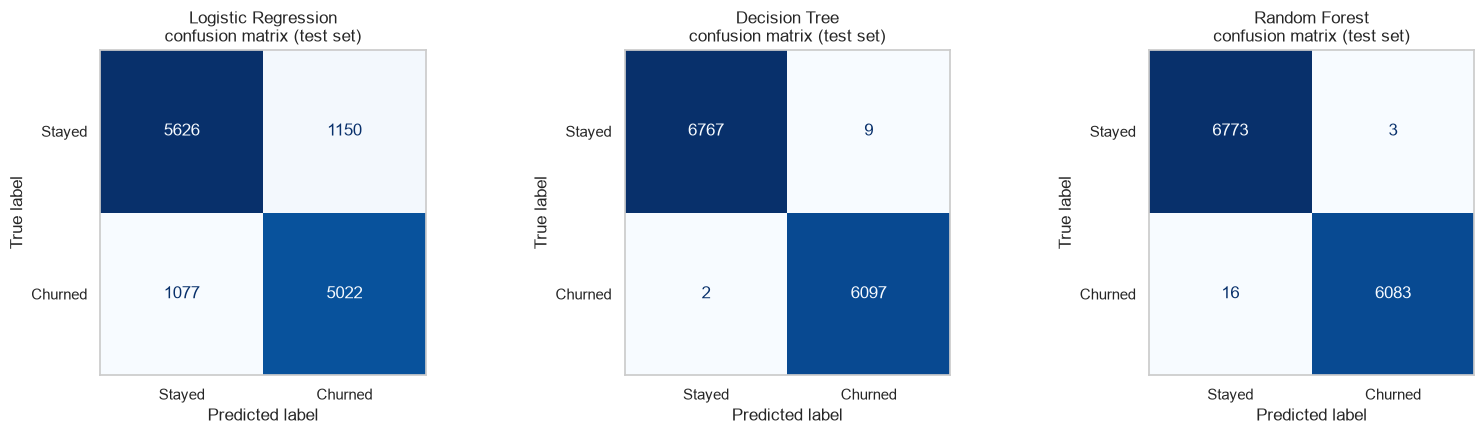

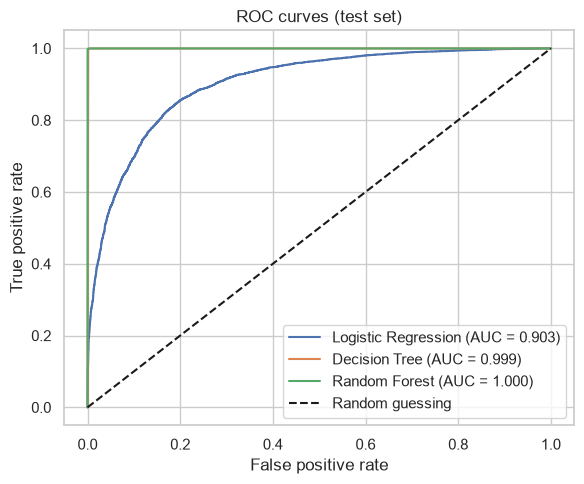

In [14]:
for name in models:
    print(f"===== {name} =====")
    print(classification_report(y_test, test_pred[name], target_names=["Stayed (0)", "Churned (1)"], digits=4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nconfusion matrix (test set)")
    ax.grid(False)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {test_results[name]['ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (test set)"); plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Cross-Validation and Leakage Checks

Scores of 99.8% are unusual for churn data, so this section investigates them instead of trusting them. **Data leakage** means the model sees information it would not have in real use (for example the answer itself, or a column derived from it).

Checks performed:
1. Cross-validation on the training set only.
2. Confirm preprocessing is fitted on training data only.
3. `CustomerID` and row order.
4. Dataset segments and per-segment performance.
5. Is churn a near-deterministic rule of the features? (depth sweep and drop-one-feature test)
6. Duplicates and train/test overlap; signs of synthetic data.
7. Label-shuffle sanity test.

In [15]:
# 10.1 Stratified k-fold cross-validation on the TRAINING set only (the test set is never touched here)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "roc_auc": "roc_auc",
    "neg_log_loss": "neg_log_loss",
}

cv_mean, cv_std = {}, {}
for name, model in {"Baseline (majority class)": baseline_model, **models}.items():
    scores = cross_validate(model, x_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_mean[name] = {m: scores[f"test_{m}"].mean() for m in scoring}
    cv_std[name] = {m: scores[f"test_{m}"].std() for m in scoring}

cv_mean = pd.DataFrame(cv_mean).T
cv_std = pd.DataFrame(cv_std).T
cv_display = cv_mean.round(4).astype(str) + " +/- " + cv_std.round(4).astype(str)
cv_display.columns = ["Accuracy", "Precision (churn)", "Recall (churn)", "F1 (churn)", "ROC AUC", "Neg. log loss"]
print(f"{CV_FOLDS}-fold stratified CV on the training set (mean +/- standard deviation across folds):")
display(cv_display)

5-fold stratified CV on the training set (mean +/- standard deviation across folds):


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC AUC,Neg. log loss
Baseline (majority class),0.5263 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.5 +/- 0.0,-17.0731 +/- 0.0007
Logistic Regression,0.8261 +/- 0.0052,0.8094 +/- 0.007,0.8277 +/- 0.0047,0.8185 +/- 0.0051,0.9045 +/- 0.0037,-0.3928 +/- 0.0071
Decision Tree,0.9984 +/- 0.0004,0.9982 +/- 0.0003,0.9985 +/- 0.0006,0.9983 +/- 0.0004,0.9984 +/- 0.0004,-0.0567 +/- 0.0139
Random Forest,0.9984 +/- 0.0003,0.999 +/- 0.0003,0.9975 +/- 0.0007,0.9983 +/- 0.0003,1.0 +/- 0.0,-0.0498 +/- 0.0005


In [16]:
# 10.2 Is preprocessing fitted on the training data only?
# If it is, the fitted scaler's mean equals the TRAINING mean (not the test or the full-data mean).
scaler = models["Logistic Regression"].named_steps["preprocessor"].named_transformers_["num"]
check = pd.DataFrame({
    "scaler mean (fitted)": scaler.mean_,
    "x_train mean": x_train[numerical_features].mean().values,
    "x_test mean": x_test[numerical_features].mean().values,
    "full-data mean": x[numerical_features].mean().values,
}, index=numerical_features).round(4)
display(check)
assert np.allclose(scaler.mean_, x_train[numerical_features].mean().values), "Scaler was not fitted on training data only!"
print("OK: the scaler was fitted on the training data only. Cross-validation also re-fits the whole pipeline inside every fold.")

,scaler mean (fitted),x_train mean,x_test mean,full-data mean
Age,42.0320,42.0320,41.7271,41.9710
Tenure,32.0095,32.0095,31.9362,31.9948
Usage Frequency,15.0681,15.0681,15.1289,15.0802
Support Calls,5.3966,5.3966,5.4172,5.4007
Payment Delay,17.1246,17.1246,17.1713,17.1340
Total Spend,540.9831,540.9831,541.1845,541.0234
Last Interaction,15.5034,15.5034,15.4807,15.4989


OK: the scaler was fitted on the training data only. Cross-validation also re-fits the whole pipeline inside every fold.


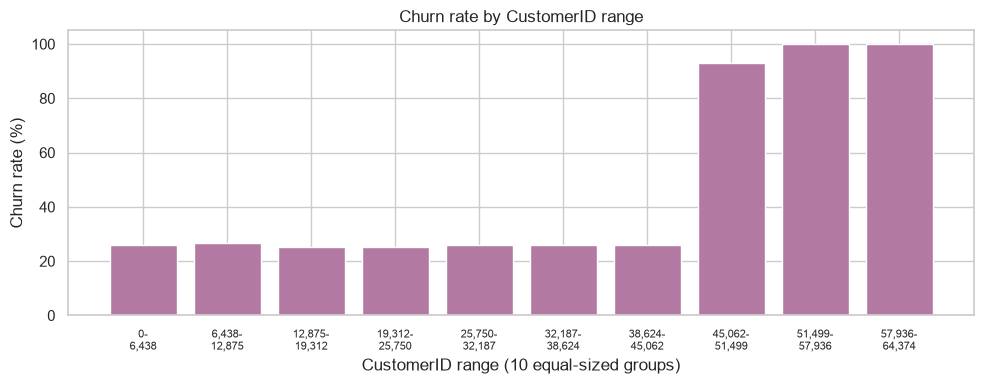

Correlation of CustomerID with Churn: 0.530
Accuracy of a tiny tree that sees ONLY CustomerID (shuffled 5-fold CV): 0.817
-> CustomerID alone predicts churn far better than chance, because the file is sorted: it is an artifact of row order.
   It is correctly EXCLUDED from the features, and must never be added back.


In [ ]:
# 10.3 CustomerID and row order
id_bins = pd.qcut(df[ID_COLUMN], 10)
id_rate = df.groupby(id_bins, observed=True)[TARGET].mean() * 100

plt.figure(figsize=(10, 4))
plt.bar(range(10), id_rate.values, color="#B279A2")
plt.xticks(range(10), [f"{int(iv.left):,}-\n{int(iv.right):,}" for iv in id_rate.index], fontsize=8)
plt.ylabel("Churn rate (%)"); plt.xlabel("CustomerID range (10 equal-sized groups)")
plt.title("Churn rate by CustomerID range")
plt.tight_layout()
plt.show()

id_only_acc = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
                            df[[ID_COLUMN]], df[TARGET], cv=cv, scoring="accuracy").mean()
print(f"Correlation of CustomerID with Churn: {df[ID_COLUMN].corr(df[TARGET]):.3f}")
print(f"Accuracy of a tiny tree that sees ONLY CustomerID (shuffled 5-fold CV): {id_only_acc:.3f}")
print("-> CustomerID alone predicts churn far better than chance, because the file is sorted: it is an artifact of row order.")
print("   It is correctly EXCLUDED from the features, and must never be added back.")

In [18]:
# 10.4 Two segments in the file
last_stay_id = int(df.loc[df[TARGET] == 0, ID_COLUMN].max())
segment = np.where(df[ID_COLUMN] <= last_stay_id, "A: IDs up to last non-churner", "B: IDs after last non-churner")
df_seg = df.assign(Segment=segment)
print(f"Highest CustomerID with Churn = 0: {last_stay_id:,}. Every customer after that ID has Churn = 1.\n")

seg_summary = df_seg.groupby("Segment").agg(
    rows=(TARGET, "size"),
    churn_rate=(TARGET, "mean"),
    female_share=("Gender", lambda s: (s == "Female").mean()),
    mean_payment_delay=("Payment Delay", "mean"),
    mean_support_calls=("Support Calls", "mean"),
    mean_tenure=("Tenure", "mean"),
).round(3)
display(seg_summary)

# Does the model only look good because of segment B? Evaluate each model on test rows of each segment.
test_segment = np.where(df.loc[x_test.index, ID_COLUMN] <= last_stay_id, "A", "B")
rows = []
for name, model in models.items():
    for seg_name in ["A", "B"]:
        mask = test_segment == seg_name
        rows.append({
            "Model": name, "Segment": seg_name, "Test rows": int(mask.sum()),
            "Accuracy": accuracy_score(y_test[mask], test_pred[name][mask]),
            "Recall (churn)": recall_score(y_test[mask], test_pred[name][mask], pos_label=1, zero_division=0),
        })
print("Full-data models, test rows split by segment:")
display(pd.DataFrame(rows).round(4))

# Sensitivity analysis: retrain and re-test using ONLY segment A (more natural 26% churn rate)
seg_a = df_seg[df_seg["Segment"].str.startswith("A")]
xa, ya = seg_a[x.columns], seg_a[TARGET]
xa_train, xa_test, ya_train, ya_test = train_test_split(xa, ya, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=ya)
rows = []
for name, model in make_models().items():
    model.fit(xa_train, ya_train)
    m, _, _ = evaluate_model(name, model, xa_test, ya_test)
    rows.append(m)
print("\nSensitivity analysis - trained AND tested on segment A only (not used for final model selection):")
display(pd.DataFrame(rows).set_index("Model").round(4))

Highest CustomerID with Churn = 0: 45,684. Every customer after that ID has Churn = 1.



,rows,churn_rate,female_share,mean_payment_delay,mean_support_calls,mean_tenure
Segment,,,,,,
A: IDs up to last non-churner,45684,0.258,0.499,15.023,4.993,30.541
B: IDs after last non-churner,18690,1.000,0.618,22.293,6.398,35.548


Full-data models, test rows split by segment:


,Model,Segment,Test rows,Accuracy,Recall (churn)
0,Logistic Regression,A,9095,0.8287,0.8241
1,Logistic Regression,B,3780,0.8230,0.8230
2,Decision Tree,A,9095,0.9988,0.9991
3,Decision Tree,B,3780,1.0000,1.0000
4,Random Forest,A,9095,0.9989,0.9970
5,Random Forest,B,3780,0.9976,0.9976



Sensitivity analysis - trained AND tested on segment A only (not used for final model selection):


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC AUC
Model,,,,,
Logistic Regression,0.8531,0.7524,0.6434,0.6936,0.9053
Decision Tree,0.9967,0.9936,0.9936,0.9936,0.9957
Random Forest,0.9950,1.0000,0.9805,0.9902,1.0000


In [19]:
# 10.5 Is churn a near-deterministic rule of the features?
# A single decision tree reaching ~99.8% means a compact set of if-then rules reproduces the label.
depth_rows = []
for depth in [2, 4, 6, 8, 12, None]:
    pipe = build_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    acc = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy").mean()
    depth_rows.append({"max_depth": "unlimited" if depth is None else depth, "CV accuracy": round(acc, 4)})
print("Single decision tree, CV accuracy by depth (training set):")
display(pd.DataFrame(depth_rows))

full_tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(x_train, y_train).named_steps["classifier"]
print(f"Unrestricted tree: depth = {full_tree.get_depth()}, leaves = {full_tree.get_n_leaves()}")

# Drop-one-feature test: which inputs does the rule actually need?
reference = cross_val_score(build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), x_train, y_train, cv=cv, scoring="accuracy").mean()
drop_rows = []
for feature in x_train.columns:
    num_cols = [c for c in numerical_features if c != feature]
    cat_cols = [c for c in categorical_features if c != feature]
    pipe = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), num_cols, cat_cols)
    acc = cross_val_score(pipe, x_train[num_cols + cat_cols], y_train, cv=cv, scoring="accuracy").mean()
    drop_rows.append({"Feature removed": feature, "CV accuracy": round(acc, 4), "Change vs all features": round(acc - reference, 4)})
print(f"\nDecision tree CV accuracy with all features: {reference:.4f}")
display(pd.DataFrame(drop_rows).sort_values("CV accuracy"))

Single decision tree, CV accuracy by depth (training set):


,max_depth,CV accuracy
0,2,0.8180
1,4,0.9418
2,6,0.9797
3,8,0.9956
4,12,0.9984
5,unlimited,0.9984


Unrestricted tree: depth = 13, leaves = 114

Decision tree CV accuracy with all features: 0.9984


,Feature removed,CV accuracy,Change vs all features
5,Payment Delay,0.7271,-0.2713
4,Support Calls,0.8658,-0.1326
2,Tenure,0.8995,-0.0989
3,Usage Frequency,0.9200,-0.0785
1,Gender,0.9307,-0.0677
8,Total Spend,0.9581,-0.0403
7,Contract Length,0.9610,-0.0374
0,Age,0.9632,-0.0353
6,Subscription Type,0.9964,-0.0020
9,Last Interaction,0.9986,0.0001


In [20]:
# 10.6 Duplicates / train-test overlap, and signs of synthetic data
dup_features = int(x.duplicated().sum())
overlap = x_test.merge(x_train.drop_duplicates(), on=list(x.columns), how="inner").shape[0]
print(f"Rows with identical feature values (excluding ID and target): {dup_features}")
print(f"Test rows whose exact feature combination also appears in the training set: {overlap}")

# Are the numeric features in segment A consistent with independent uniform random draws?
# For uniform draws the relative spread of value counts is about sqrt((k-1)/n); a ratio near 1 means 'consistent'.
rows = []
for col in numerical_features:
    counts = seg_a[col].value_counts()
    k, n = counts.size, len(seg_a)
    rows.append({"Feature": col, "min": seg_a[col].min(), "max": seg_a[col].max(), "distinct values": k,
                 "observed / expected spread": round((counts.std() / counts.mean()) / np.sqrt((k - 1) / n), 2)})
print("\nSegment A: how uniform are the numeric features? (ratio close to 1.0 = consistent with uniform random draws)")
display(pd.DataFrame(rows))
print("Gender share in segment A:", seg_a["Gender"].value_counts(normalize=True).round(3).to_dict())
print("Pairwise correlations among features in segment A (max absolute value):",
      round(seg_a[numerical_features].corr().where(~np.eye(len(numerical_features), dtype=bool)).abs().max().max(), 3))

Rows with identical feature values (excluding ID and target): 0
Test rows whose exact feature combination also appears in the training set: 0

Segment A: how uniform are the numeric features? (ratio close to 1.0 = consistent with uniform random draws)


,Feature,min,max,distinct values,observed / expected spread
0,Age,18,65,48,1.23
1,Tenure,1,60,60,1.00
2,Usage Frequency,1,30,30,0.78
3,Support Calls,0,10,11,0.99
4,Payment Delay,0,30,31,0.92
5,Total Spend,100,1000,901,1.00
6,Last Interaction,1,30,30,0.97


Gender share in segment A: {'Male': 0.501, 'Female': 0.499}
Pairwise correlations among features in segment A (max absolute value): 0.015


In [21]:
# 10.7 Label-shuffle sanity test: if the pipeline itself leaked the answer, scores would stay high even with random labels.
rng = np.random.RandomState(RANDOM_STATE)
y_train_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
shuffle_model = build_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
shuffle_model.fit(x_train, y_train_shuffled)
shuffle_acc = accuracy_score(y_test, shuffle_model.predict(x_test))
print(f"Random Forest trained on SHUFFLED labels -> accuracy on the real test labels: {shuffle_acc:.4f}")
print(f"(majority-class baseline accuracy: {test_results['Baseline (majority class)']['Accuracy']:.4f}; chance level is about 0.5)")

Random Forest trained on SHUFFLED labels -> accuracy on the real test labels: 0.5102
(majority-class baseline accuracy: 0.5263; chance level is about 0.5)


### Leakage check - verdict

| Check | Result | Status |
|---|---|---|
| Preprocessing fitted on training data only | Fitted scaler means equal the training means exactly (10.2); CV refits the pipeline inside each fold | **Verified OK** |
| Test set used for fitting, selection or tuning | No. Model selection uses training-set CV only (Section 11); no hyper-parameter tuning was done | **Verified OK** |
| Duplicate rows / train-test overlap | 0 duplicate feature rows; 0 test rows share a feature combination with training rows (10.6) | **Verified OK** |
| Label-shuffle test | Random Forest trained on shuffled labels scores about 0.51 on the real test labels, so the pipeline itself does not leak the answer (10.7) | **Verified OK** |
| `CustomerID` | Not used as a feature. Alone, it predicts churn with about 82% accuracy because the file is sorted by outcome (10.3). Excluding it is correct | **Verified; correctly excluded** |
| A single feature that reveals the target | No single feature reproduces the label. The most important one, Payment Delay, drops accuracy to about 73% when removed; the label depends on many features combined (10.5). `Last Interaction` has no measurable effect | **No direct leakage found** |
| Unusual 100%-churn block of rows | Every customer after ID 45,684 (18,690 rows, 29% of the file) churned, and these rows differ in make-up from the rest (61.8% female vs 49.9%; mean payment delay 22.3 vs 15.0 days). Real customer data would not behave like this; it points to how the file was assembled (10.4). Trained and tested on only the other 45,684 rows, Decision Tree and Random Forest still reach about 99.5% accuracy or higher, so this block alone does not explain the high scores | **Dataset artifact - unresolved** |
| Near-perfect scores of Decision Tree / Random Forest | A single decision tree reaches about 99.8% CV accuracy; the rest of the data has independent, near-uniform features (max pairwise correlation 0.015) and a 50/50 gender split. This is **strongly consistent with synthetic data whose churn label was generated by rules over the features**, which trees can rediscover almost perfectly | **Suspected, not proven** |

**Conclusion.** No feature was found that directly leaks the target, and the pipeline itself is clean. The 99.8% scores are most plausibly explained by the label being (close to) a deterministic function of the features in this dataset. I could not establish from the two files who generated the data, so "synthetic" is an inference from the evidence above, not a confirmed fact. These scores should **not** be read as how accurately churn could be predicted for real customers. Logistic Regression (about 83% accuracy) shows what a simple model captures from the same features.

## 11. Final Model Selection

The final model is chosen with a **rule that is fixed in advance and uses only cross-validation results from the training set** (never the test set):

1. Compare mean cross-validated **F1 for the churn class**, because catching churners while keeping false alarms low matters more here than raw accuracy.
2. Models within `SELECTION_TOLERANCE` of the best F1 are treated as tied (their difference is smaller than fold-to-fold noise).
3. Among tied models, choose the one with the best **log loss**, because the prediction function reports a churn *probability* and a model with better-calibrated probabilities is more useful.

The test-set numbers are reported for the chosen model afterwards and were not used to choose it.

In [22]:
SELECTION_TOLERANCE = 0.002

candidates = cv_mean.loc[list(models)]
best_f1 = candidates["f1"].max()
shortlist = candidates[candidates["f1"] >= best_f1 - SELECTION_TOLERANCE]
final_model_name = shortlist["neg_log_loss"].idxmax()
final_model = models[final_model_name]          # already fitted on the training set only

print("Cross-validated scores used for selection (training set):")
display(candidates[["f1", "recall", "precision", "accuracy", "roc_auc", "neg_log_loss"]].round(4))
print(f"Best mean CV F1: {best_f1:.4f}; models within {SELECTION_TOLERANCE} of it: {shortlist.index.tolist()}")
print(f"-> Selected final model: {final_model_name}")

print("\nHold-out test-set metrics of the selected model (reported once, not used for selection):")
display(test_table.loc[[final_model_name]].round(4))

Cross-validated scores used for selection (training set):


,f1,recall,precision,accuracy,roc_auc,neg_log_loss
Logistic Regression,0.8185,0.8277,0.8094,0.8261,0.9045,-0.3928
Decision Tree,0.9983,0.9985,0.9982,0.9984,0.9984,-0.0567
Random Forest,0.9983,0.9975,0.9990,0.9984,1.0000,-0.0498


Best mean CV F1: 0.9983; models within 0.002 of it: ['Decision Tree', 'Random Forest']
-> Selected final model: Random Forest

Hold-out test-set metrics of the selected model (reported once, not used for selection):


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC AUC
Model,,,,,
Random Forest,0.9985,0.9995,0.9974,0.9984,1.0


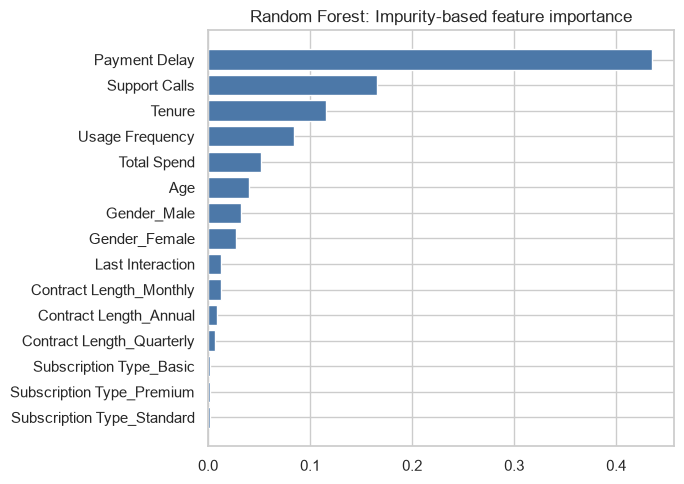

Note: importance describes what the model uses, not what causes churn. Impurity-based importance can also favour numeric features with many distinct values.


In [23]:
# Which features does the final model rely on? (impurity-based importance for tree models, |coefficient| for logistic regression)
prep = final_model.named_steps["preprocessor"]
clf = final_model.named_steps["classifier"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
if hasattr(clf, "feature_importances_"):
    importance = pd.Series(clf.feature_importances_, index=feature_names); label = "Impurity-based feature importance"
else:
    importance = pd.Series(np.abs(clf.coef_[0]), index=feature_names); label = "|Coefficient| (standardised features)"
importance = importance.sort_values()

plt.figure(figsize=(7, 5))
plt.barh(importance.index, importance.values, color="#4C78A8")
plt.title(f"{final_model_name}: {label}")
plt.tight_layout()
plt.show()
print("Note: importance describes what the model uses, not what causes churn. Impurity-based importance can also favour numeric features with many distinct values.")

## 12. Customer Churn Prediction

`predict_churn()` takes **one customer** (a dict, a pandas Series, or a one-row DataFrame) with the 10 feature columns, validates it, and returns the prediction and churn probability from the final pipeline. Invalid input produces a clear error message instead of a crash.

Validation rules: all 10 features present, no unknown columns, numbers must be finite and non-negative, and categories must be known (matching is case-insensitive). Values outside the range seen in training only trigger a warning, because the model would be extrapolating. `CustomerID` is ignored if supplied; a supplied `Churn` value is ignored with a warning.

In [24]:
REQUIRED_FEATURES = x_train.columns.tolist()
CATEGORY_VALUES = {c: sorted(x_train[c].unique().tolist()) for c in categorical_features}
NUMERIC_RANGES = {c: (x_train[c].min(), x_train[c].max()) for c in numerical_features}
CHURN_CLASS_INDEX = list(final_model.classes_).index(POSITIVE_CLASS)


def validate_customer_input(customer_data):
    """Convert input to a one-row DataFrame in training-column order.

    Returns (row, warnings). Raises ValueError(list_of_messages) if the input is invalid.
    """
    if isinstance(customer_data, pd.DataFrame):
        if len(customer_data) != 1:
            raise ValueError([f"Provide exactly one customer (got {len(customer_data)} rows)."])
        record = customer_data.iloc[0].to_dict()
    elif isinstance(customer_data, pd.Series):
        record = customer_data.to_dict()
    elif isinstance(customer_data, dict):
        record = dict(customer_data)
    else:
        raise ValueError([f"Unsupported input type {type(customer_data).__name__}; use a dict, pandas Series or one-row DataFrame."])

    problems, notes = [], []

    if ID_COLUMN in record:
        record.pop(ID_COLUMN)
    if TARGET in record:
        record.pop(TARGET)
        notes.append(f"'{TARGET}' was supplied and ignored; it is the value being predicted.")

    missing_cols = [c for c in REQUIRED_FEATURES if c not in record]
    unknown_cols = [c for c in record if c not in REQUIRED_FEATURES]
    if missing_cols:
        problems.append(f"Missing required feature(s): {missing_cols}")
    if unknown_cols:
        problems.append(f"Unknown column(s): {unknown_cols}. Expected: {REQUIRED_FEATURES}")

    clean = {}
    for col in numerical_features:
        if col not in record:
            continue
        value = pd.to_numeric(pd.Series([record[col]]), errors="coerce").iloc[0]
        if pd.isna(value) or not np.isfinite(value):
            problems.append(f"'{col}' must be a finite number (got {record[col]!r}).")
        elif value < 0:
            problems.append(f"'{col}' must be non-negative (got {record[col]!r}).")
        else:
            low, high = NUMERIC_RANGES[col]
            if not low <= value <= high:
                notes.append(f"'{col}'={value} is outside the training range [{low}, {high}]; the prediction is an extrapolation.")
            clean[col] = value
    for col in categorical_features:
        if col not in record:
            continue
        lookup = {v.lower(): v for v in CATEGORY_VALUES[col]}
        key = str(record[col]).strip().lower()
        if key in lookup:
            clean[col] = lookup[key]
        else:
            problems.append(f"'{col}' must be one of {CATEGORY_VALUES[col]} (got {record[col]!r}).")

    if problems:
        raise ValueError(problems)
    return pd.DataFrame([clean])[REQUIRED_FEATURES], notes


def predict_churn(customer_data):
    """ML-only prediction for one customer (no Gemini). Never raises for bad input; returns ok=False with errors."""
    try:
        row, notes = validate_customer_input(customer_data)
    except ValueError as err:
        return {"ok": False, "errors": err.args[0]}
    prediction = int(final_model.predict(row)[0])
    probability = float(final_model.predict_proba(row)[0][CHURN_CLASS_INDEX])
    return {
        "ok": True,
        "prediction": prediction,
        "prediction_label": "Likely to Churn" if prediction == POSITIVE_CLASS else "Likely to Stay",
        "churn_probability": round(probability, 4),
        "model": final_model_name,
        "warnings": notes,
        "input": {k: (v.item() if hasattr(v, "item") else v) for k, v in row.iloc[0].items()},
    }
print("Validation and ML prediction functions defined.")

Validation and ML prediction functions defined.


In [25]:
# Test 1: a valid sample taken from the test set
sample_customer = x_test.iloc[[0]]
result = predict_churn(sample_customer)
print("Sample customer (from test set):", result["input"])
print(f"Prediction: {result['prediction']} ({result['prediction_label']}) | churn probability: {result['churn_probability']:.2%} | actual label: {int(y_test.iloc[0])}")

# The function must agree exactly with calling the pipeline directly
assert result["prediction"] == int(final_model.predict(sample_customer)[0])
assert abs(result["churn_probability"] - final_model.predict_proba(sample_customer)[0][CHURN_CLASS_INDEX]) < 1e-4
assert 0.0 <= result["churn_probability"] <= 1.0
print("OK: output matches the pipeline.")

# Test 2: dict input with different capitalisation
as_dict = {**x_test.iloc[0].to_dict(), "Gender": "male", "CustomerID": 123}
assert predict_churn(as_dict)["ok"]
print("OK: dict input with lowercase category and an ignored CustomerID works.")

# Test 3: invalid inputs are reported, not crashed on
bad_inputs = {
    "missing feature": {k: v for k, v in x_test.iloc[0].to_dict().items() if k != "Tenure"},
    "unknown category": {**x_test.iloc[0].to_dict(), "Subscription Type": "Platinum"},
    "negative number": {**x_test.iloc[0].to_dict(), "Age": -5},
    "non-numeric value": {**x_test.iloc[0].to_dict(), "Total Spend": "lots"},
    "typo in column name": {**{k: v for k, v in x_test.iloc[0].to_dict().items() if k != "Support Calls"}, "Support calls": 3},
    "wrong input type": [1, 2, 3],
}
for label, bad in bad_inputs.items():
    out = predict_churn(bad)
    assert out["ok"] is False
    print(f"  {label:<20} -> rejected: {out['errors'][0][:95]}")

# Test 4: out-of-range value -> warning, still predicts
odd = predict_churn({**x_test.iloc[0].to_dict(), "Age": 120})
assert odd["ok"] and odd["warnings"]
print("OK: out-of-range Age gives a warning:", odd["warnings"][0])

Sample customer (from test set): {'Age': 26, 'Gender': 'Male', 'Tenure': 51, 'Usage Frequency': 19, 'Support Calls': 6, 'Payment Delay': 3, 'Subscription Type': 'Premium', 'Contract Length': 'Quarterly', 'Total Spend': 761, 'Last Interaction': 21}
Prediction: 0 (Likely to Stay) | churn probability: 1.00% | actual label: 0
OK: output matches the pipeline.
OK: dict input with lowercase category and an ignored CustomerID works.
  missing feature      -> rejected: Missing required feature(s): ['Tenure']
  unknown category     -> rejected: 'Subscription Type' must be one of ['Basic', 'Premium', 'Standard'] (got 'Platinum').
  negative number      -> rejected: 'Age' must be non-negative (got -5).
  non-numeric value    -> rejected: 'Total Spend' must be a finite number (got 'lots').
  typo in column name  -> rejected: Missing required feature(s): ['Support Calls']
  wrong input type     -> rejected: Unsupported input type list; use a dict, pandas Series or one-row DataFrame.
OK: out-of-range

In [26]:
# Test-set prediction summary (kept from the original notebook, now with the actual rate for comparison)
churn_predictions = final_model.predict(x_test)
churn_probabilities = final_model.predict_proba(x_test)[:, CHURN_CLASS_INDEX]

print("Customer churn summary (test set)")
print("---------------------------------")
print("Total customers:        ", len(y_test))
print("Predicted to churn:     ", int(churn_predictions.sum()), f"({churn_predictions.mean():.2%})")
print("Predicted to stay:      ", len(y_test) - int(churn_predictions.sum()))
print("Actual churn rate:      ", f"{y_test.mean():.2%}")

prediction_df = x_test.copy()
prediction_df["Actual_Churn"] = y_test.values
prediction_df["Predicted_Churn"] = churn_predictions
prediction_df["Churn_Probability"] = churn_probabilities.round(4)
prediction_df.head(10)

Customer churn summary (test set)
---------------------------------
Total customers:         12875
Predicted to churn:      6086 (47.27%)
Predicted to stay:       6789
Actual churn rate:       47.37%


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Actual_Churn,Predicted_Churn,Churn_Probability
7437,26,Male,51,19,6,3,Premium,Quarterly,761,21,0,0,0.01
54961,51,Female,7,4,7,0,Basic,Monthly,612,4,1,1,0.86
33685,52,Male,23,28,1,24,Premium,Annual,937,24,0,0,0.01
20607,48,Male,57,30,10,0,Standard,Monthly,362,22,0,0,0.04
34098,41,Female,45,27,5,9,Basic,Monthly,675,27,0,0,0.01
25054,26,Female,44,6,0,0,Basic,Monthly,226,11,0,0,0.02
21914,20,Male,45,10,0,19,Premium,Annual,606,20,0,0,0.03
42952,29,Female,4,16,5,2,Standard,Quarterly,796,26,0,0,0.01
26694,54,Male,31,27,7,11,Basic,Quarterly,412,28,0,0,0.01
18601,56,Female,28,8,7,6,Standard,Quarterly,542,21,0,0,0.03


## 13. Gemini-Powered Explanation

Gemini writes a short, plain-language explanation of a prediction. Design rules:

* **The explanation never changes the prediction.** The ML result is computed first; the Gemini call is wrapped so that any failure (no key, no package, 503, rate limit, empty reply) still returns the ML result.
* **No secrets in the notebook.** The key is read from the `GEMINI_API_KEY` (or `GOOGLE_API_KEY`) environment variable. Set `PROMPT_FOR_GEMINI_KEY = True` below to type it into a hidden prompt instead. It is never printed.
* **The prompt forbids invented facts**: Gemini only sees the customer's feature values, the model's label and probability, and is told to describe possible associations rather than proven causes.
* **Model names:** `gemini-3.8-flash` and the fallbacks below appear in the model list that your own account printed in the original notebook. I could not verify them independently, so the code can re-check them against your live model list (see the last cell of this section). The `503 UNAVAILABLE ... high demand` error in your original output is a temporary capacity message from the service, not evidence that the name is wrong.

In [32]:
# ---- Gemini configuration ----
PROMPT_FOR_GEMINI_KEY = True          # set True to be asked for the key in a hidden prompt when no environment variable exists
GEMINI_RETRIES_PER_MODEL = 2           # attempts per model for temporary errors
GEMINI_BACKOFF_SECONDS = 2             # wait doubles after each failed attempt (2s, 4s, ...)

_requested = os.environ.get("GEMINI_MODEL", "gemini-3.8-flash")
GEMINI_MODEL_CANDIDATES = list(dict.fromkeys([_requested, "gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.6-flash", "gemini-3.5-flash"]))

_gemini_secrets = []                   # used only to scrub the key out of error messages


def create_gemini_client(prompt_if_missing=False):
    """Return (client, problem). `client` is None if Gemini cannot be used; `problem` says why."""
    try:
        from google import genai
    except ImportError:
        return None, "The 'google-genai' package is not installed (pip install -U google-genai)."
    api_key = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
    if not api_key and prompt_if_missing:
        from getpass import getpass
        api_key = getpass("Enter your Gemini API key (input is hidden): ").strip()
    if not api_key:
        return None, "No API key found. Set the GEMINI_API_KEY environment variable and re-run this cell."
    _gemini_secrets.append(api_key)
    try:
        return genai.Client(api_key=api_key), None
    except Exception as err:
        return None, f"Could not create the Gemini client ({type(err).__name__})."


gemini_client, gemini_problem = create_gemini_client(PROMPT_FOR_GEMINI_KEY)
print("Gemini client ready." if gemini_client else f"Gemini is not available: {gemini_problem}")
print("Models that will be tried, in order:", GEMINI_MODEL_CANDIDATES)

Gemini client ready.
Models that will be tried, in order: ['gemini-3.8-flash', 'gemini-3.7-flash', 'gemini-3.6-flash', 'gemini-3.5-flash']


In [28]:
def _scrub(text):
    """Remove any API key from a message before it is stored or printed."""
    text = str(text)
    for secret in _gemini_secrets:
        text = text.replace(secret, "[REDACTED]")
    return text[:300]


def _classify_error(error):
    """Return 'transient' (retry), 'auth' (stop everything) or 'other' (try the next model)."""
    code = getattr(error, "code", None)
    if isinstance(code, int):
        if code in (429, 500, 502, 503, 504):
            return "transient"
        if code in (401, 403):
            return "auth"
        return "other"
    if isinstance(error, (ConnectionError, TimeoutError)):
        return "transient"
    text = str(error).lower()
    if any(w in text for w in ("unavailable", "resource_exhausted", "timed out", "timeout", "connection")):
        return "transient"
    return "other"


def build_explanation_prompt(customer, label, probability):
    return f"""You are a customer-churn analysis assistant. A machine-learning model produced the prediction below.
It is a statistical output learned from a dataset. It is NOT proof of why this customer will or will not leave.

Customer details (the ONLY customer facts you may use):
{json.dumps(customer, indent=2, default=str)}

Model output:
- Prediction: {label}
- Estimated churn probability: {probability:.1%} (a prediction of 'churn' means probability >= 50%)

Write, in under 200 words:
1. A plain-language summary of the prediction.
2. Which of the listed customer details might be relevant, phrased as possible associations, not proven causes.
3. Two practical, low-risk customer-retention suggestions that do not assume any facts that were not given.

Rules: do not invent customer information (names, history, complaints, reasons); do not claim certainty about causes; do not use low/medium/high risk labels."""


def explain_with_gemini(customer, label, probability, client, models=None, retries=None, sleep=time.sleep):
    """Ask Gemini for an explanation. NEVER raises; always returns a dict describing what happened."""
    models = models or GEMINI_MODEL_CANDIDATES
    retries = GEMINI_RETRIES_PER_MODEL if retries is None else retries
    out = {"available": False, "text": None, "model": None, "error": None, "attempts": []}
    if client is None:
        out["error"] = "Gemini client is not available."
        return out
    try:
        prompt = build_explanation_prompt(customer, label, probability)
        for model_name in models:
            for attempt in range(1, retries + 1):
                try:
                    response = client.models.generate_content(model=model_name, contents=prompt)
                    text = (getattr(response, "text", None) or "").strip()
                    if not text:
                        out["attempts"].append((model_name, attempt, "empty response"))
                        out["error"] = f"{model_name} returned an empty response."
                        break                                   # try next model
                    out.update(available=True, text=text, model=model_name, error=None)
                    out["attempts"].append((model_name, attempt, "ok"))
                    return out
                except Exception as err:
                    kind = _classify_error(err)
                    out["error"] = f"{model_name}: {type(err).__name__}: {_scrub(err)}"
                    out["attempts"].append((model_name, attempt, kind))
                    if kind == "auth":
                        return out                              # bad key / permission: other models will fail too
                    if kind == "transient" and attempt < retries:
                        sleep(GEMINI_BACKOFF_SECONDS * 2 ** (attempt - 1))
                        continue                                # retry same model
                    break                                       # next model
    except Exception as err:                                    # absolute safety net
        out["error"] = f"Unexpected error while contacting Gemini: {type(err).__name__}: {_scrub(err)}"
    return out


def predict_customer_churn(customer_data, explain=True, client=None, sleep=time.sleep):
    """FINAL prediction function.

    1. Validates the input and computes the ML prediction + churn probability (always).
    2. Optionally adds a Gemini explanation under result['explanation'] - kept separate from the prediction.
    """
    result = predict_churn(customer_data)
    if not result["ok"] or not explain:
        return result
    if client is None:
        client = globals().get("gemini_client")
    gem = explain_with_gemini(result["input"], result["prediction_label"], result["churn_probability"], client, sleep=sleep)
    result["explanation"] = {
        "source": "Gemini (AI-generated, informational only; it does not influence the prediction)",
        "available": gem["available"], "text": gem["text"], "model": gem["model"],
        "error": gem["error"], "attempts": gem["attempts"],
    }
    return result


def show_prediction(result):
    if not result["ok"]:
        print("Invalid input:"); [print(" -", e) for e in result["errors"]]; return
    print("========== ML PREDICTION (from the trained model) ==========")
    print("Prediction:       ", result["prediction_label"], f"(class {result['prediction']})")
    print("Churn probability:", f"{result['churn_probability']:.2%}")
    for w in result["warnings"]:
        print("Warning:", w)
    exp = result.get("explanation")
    if exp:
        print("\n========== GEMINI EXPLANATION (AI-generated, separate from the prediction) ==========")
        print(exp["text"] if exp["available"] else f"Not available - {exp['error']}")
print("Gemini explanation functions defined.")

Gemini explanation functions defined.


In [29]:
# Tests of the failure paths using FAKE clients - no API key, network or real Gemini call needed.
class FakeAPIError(Exception):
    def __init__(self, code, message):
        super().__init__(f"{code} {message}"); self.code = code

class FakeResponse:
    def __init__(self, text): self.text = text

class FakeClient:
    """behaviours: {model_name: [outcome, ...]}; an outcome is an Exception to raise or a string to return."""
    def __init__(self, behaviours):
        self.calls, self._b = [], {k: list(v) for k, v in behaviours.items()}
        self.models = self
    def generate_content(self, model, contents):
        self.calls.append(model)
        outcome = self._b.get(model, [FakeAPIError(404, "NOT_FOUND")]).pop(0)
        if isinstance(outcome, Exception): raise outcome
        return FakeResponse(outcome)

no_sleep = lambda seconds: None
m1, m2 = GEMINI_MODEL_CANDIDATES[:2]
ml_only = predict_churn(sample_customer)

def same_ml(r):
    return all(r[k] == ml_only[k] for k in ("prediction", "prediction_label", "churn_probability"))

# a) every call fails with 503 -> ML result still returned, explanation reported unavailable
c = FakeClient({m: [FakeAPIError(503, "UNAVAILABLE high demand")] * 5 for m in GEMINI_MODEL_CANDIDATES})
r = predict_customer_churn(sample_customer, client=c, sleep=no_sleep)
assert r["ok"] and same_ml(r) and not r["explanation"]["available"] and "503" in r["explanation"]["error"]
print("a) all-503: ML result intact; explanation unavailable after", len(c.calls), "attempts")

# b) first model keeps failing, second model works -> fallback used
c = FakeClient({m1: [FakeAPIError(503, "UNAVAILABLE")] * 2, m2: ["Mock explanation text."]})
r = predict_customer_churn(sample_customer, client=c, sleep=no_sleep)
assert same_ml(r) and r["explanation"]["available"] and r["explanation"]["model"] == m2 and c.calls == [m1, m1, m2]
print("b) fallback to the next model works:", c.calls)

# c) empty responses -> handled
c = FakeClient({m: [""] for m in GEMINI_MODEL_CANDIDATES})
r = predict_customer_churn(sample_customer, client=c, sleep=no_sleep)
assert same_ml(r) and not r["explanation"]["available"] and "empty" in r["explanation"]["error"]
print("c) empty response handled")

# d) 401 (bad key) -> stops immediately instead of hammering every model
c = FakeClient({m: [FakeAPIError(401, "UNAUTHENTICATED")] for m in GEMINI_MODEL_CANDIDATES})
r = predict_customer_churn(sample_customer, client=c, sleep=no_sleep)
assert same_ml(r) and len(c.calls) == 1
print("d) auth error stops after", len(c.calls), "call")

# e) no client at all
if gemini_client is None:
    r = predict_customer_churn(sample_customer, client=None, sleep=no_sleep)
    assert same_ml(r) and not r["explanation"]["available"]
    print("e) no client: ML result intact; explanation unavailable ->", r["explanation"]["error"])

# f) an API key must never be shown in stored errors
_gemini_secrets.append("SECRET-TEST-KEY-123")
c = FakeClient({m: [FakeAPIError(400, "bad request SECRET-TEST-KEY-123")] for m in GEMINI_MODEL_CANDIDATES})
r = predict_customer_churn(sample_customer, client=c, sleep=no_sleep)
assert "SECRET-TEST-KEY-123" not in json.dumps(r["explanation"], default=str)
_gemini_secrets.remove("SECRET-TEST-KEY-123")
print("f) secrets are scrubbed from error messages")

# g) invalid customer input never reaches Gemini
c = FakeClient({})
r = predict_customer_churn({"Age": 30}, client=c, sleep=no_sleep)
assert r["ok"] is False and c.calls == []
print("g) invalid input rejected before any Gemini call")
print("\nAll Gemini failure-path tests passed (these use fake clients, not the real API).")

a) all-503: ML result intact; explanation unavailable after 8 attempts
b) fallback to the next model works: ['gemini-3.8-flash', 'gemini-3.8-flash', 'gemini-3.7-flash']
c) empty response handled
d) auth error stops after 1 call
e) no client: ML result intact; explanation unavailable -> Gemini client is not available.
f) secrets are scrubbed from error messages
g) invalid input rejected before any Gemini call

All Gemini failure-path tests passed (these use fake clients, not the real API).


In [30]:
# Live call - runs only when a key and the google-genai package are available.
def check_gemini_model_names(client, wanted):
    """Compare the candidate model names with the models your account can actually see."""
    try:
        available = {m.name.replace("models/", "") for m in client.models.list()}
    except Exception as err:
        print("Could not list models:", type(err).__name__, _scrub(err)); return
    for name in wanted:
        print(f"  {name:<20}", "found in your model list" if name in available else "NOT found in your model list")

if gemini_client is None:
    print("Live Gemini call skipped:", gemini_problem)
    print("The ML prediction still works; the explanation will just say that it is unavailable:\n")
    show_prediction(predict_customer_churn(sample_customer))
else:
    print("Checking model names against your account:")
    check_gemini_model_names(gemini_client, GEMINI_MODEL_CANDIDATES)
    print()
    show_prediction(predict_customer_churn(sample_customer))

Live Gemini call skipped: No API key found. Set the GEMINI_API_KEY environment variable and re-run this cell.
The ML prediction still works; the explanation will just say that it is unavailable:

========== ML PREDICTION (from the trained model) ==========
Prediction:        Likely to Stay (class 0)
Churn probability: 1.00%

========== GEMINI EXPLANATION (AI-generated, separate from the prediction) ==========
Not available - Gemini client is not available.


## 14. Final Findings and Limitations

### What was verified in this run

* **Data:** 64,374 customers, 10 usable features, no missing values, no duplicates. Churn rate 47.4%.
* **Pipeline:** `ColumnTransformer` (StandardScaler + OneHotEncoder) inside a `Pipeline`, stratified 80/20 split, seed 42. Preprocessing is fitted on training data only (verified in 10.2).
* **Results (test set, churn = positive class):** see the table below. Logistic Regression: accuracy 0.827, F1 0.819. Decision Tree: accuracy 0.999, F1 0.999. Random Forest: accuracy 0.998, F1 0.998. A majority-class baseline gets accuracy 0.526 and F1 0.
* **Final model:** Random Forest. Decision Tree and Random Forest were tied on cross-validated F1 (0.998), so the pre-set rule picked the one with the better log loss (Random Forest, 0.050 vs 0.057).
* **Prediction function:** `predict_customer_churn()` is now defined once. It validates input, returns the label and churn probability, and was tested on a real test-set row (matching the pipeline exactly), on valid dict input, and on six kinds of invalid input.
* **Gemini failure handling:** tested with fake clients for all-503, fallback to the next model, empty replies, bad key, missing client and key scrubbing. In every case the ML prediction was returned unchanged.

### Unresolved concerns and limitations

1. **Suspiciously high scores for tree models (about 99.8%).** Evidence points to the dataset's labels being near-deterministic rules of the features (Section 10). Real-world performance is unknown. If you describe this project, say so.
2. **Unusual 100%-churn block** (IDs above 45,684). It is a property of the file, not something the notebook can fix. It was kept (nothing was deleted without justification), and a segment-A-only analysis is shown as a sensitivity check. On that subset Logistic Regression drops to recall 0.64 and F1 0.69, while the tree models stay above 0.99 F1.
3. **No hyper-parameter tuning** was done, and the default 0.5 probability threshold is used. Different thresholds were not studied.
4. **Gemini was not run live here.** The `google-genai` package, an API key and network access were unavailable in the environment where I ran the notebook, so a real successful Gemini response is unverified. The model names come from the model list printed by your original notebook; the notebook re-checks them against your live list when you run it with a key. Your original `503 UNAVAILABLE` error was a temporary capacity message.
5. **How the notebook was executed:** Jupyter was not installed in my environment, so I ran the cells in order with a Python script that mimics a notebook run (Python 3.12, pandas 3.0.2, scikit-learn 1.8.0). The stored outputs are real outputs from that run, but please do **Restart & Run All** once in your own Jupyter to confirm in your setup.
6. Feature importance describes what the model uses, not what causes churn.

In [31]:
# Final results table, generated from the run above (nothing typed by hand)
summary = test_table.copy()
summary["CV F1 (train)"] = cv_mean["f1"].reindex(summary.index)
summary["Selected"] = ["<-- final model" if n == final_model_name else "" for n in summary.index]
print("Hold-out test-set metrics (churn = positive class) with cross-validated F1 from the training set:")
display(summary.round(4))

Hold-out test-set metrics (churn = positive class) with cross-validated F1 from the training set:


,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC AUC,CV F1 (train),Selected
Model,,,,,,,
Baseline (majority class),0.5263,0.0000,0.0000,0.0000,0.5000,0.0000,
Logistic Regression,0.8270,0.8137,0.8234,0.8185,0.9030,0.8185,
Decision Tree,0.9991,0.9985,0.9997,0.9991,0.9992,0.9983,
Random Forest,0.9985,0.9995,0.9974,0.9984,1.0000,0.9983,<-- final model
